# 理解数据与机器学习准备

本notebook离线复现Packet B至D的主要证据。它用于教学，不提供临床、因果或部署结论。每一节对应探究问题，并要求解释结果如何修改总Data readiness plan。


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import pairwise_distances
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
ASSET_DIR = Path('../assets/pbl-understanding-data')
heart = pd.read_csv(ASSET_DIR / 'heart-disease-four-site.csv')
heart['disease_binary'] = (heart['num'] > 0).astype(int)
cancer_bunch = load_breast_cancer(as_frame=True)
cancer_x = cancer_bunch.data.copy()
print(heart.shape, cancer_x.shape)


(920, 17) (569, 30)


## Q1和Q2 数据对象 变量语义与结构

检查数据字典中的角色和测量尺度。不要把数字编码自动解释为连续变量。


In [2]:
dictionary = pd.read_csv(ASSET_DIR / 'packet-b-data-dictionary.csv')
scale_cases = pd.read_csv(ASSET_DIR / 'packet-b-measurement-scale-cases.csv')
structures = pd.read_csv(ASSET_DIR / 'packet-b-structure-types.csv')
display(dictionary)
display(scale_cases)
display(structures)
assert dictionary.loc[dictionary.variable.eq('cp'), 'measurement_scale'].iloc[0] == 'nominal multiclass'
assert set(scale_cases.measurement_scale) >= {'nominal','ordinal','interval','ratio'}


,variable,working_meaning,role,measurement_scale,standardize,analysis_implication
0,record_id,record identifier,identifier,nominal,No,do not treat as a numeric feature
1,site,data collection site,provenance metadata,nominal,No,stratify or audit site effects
2,age,age in years,feature,ratio continuous,Usually,median IQR correlation or model feature
3,sex,recorded sex code,feature,binary nominal,No,contingency table or encoded feature
4,cp,chest pain category,feature,nominal multiclass,No,counts chi-square or one-hot encoding
5,trestbps,resting blood pressure,feature,ratio continuous,Usually,distribution comparison or numeric feature
6,chol,serum cholesterol,feature,ratio continuous,Usually,distribution transform or numeric feature
7,fbs,fasting blood sugar threshold flag,feature,binary nominal,No,proportion or binary feature
8,restecg,resting ECG category,feature,nominal multiclass,No,counts or one-hot encoding
9,thalach,maximum heart rate,feature,ratio continuous,Usually,distribution comparison or numeric feature


,microcase_variable,example_values,measurement_scale,reason,analysis_consequence
0,collection_site,A B C,nominal,different labels without order,counts and stratification
1,disease_stage,I II III IV,ordinal,ordered but gaps are not assumed equal,ordered summaries or ordinal model
2,calendar_year,2018 2019 2020,interval,differences are meaningful but year zero is ar...,differences and trends not meaningful ratios
3,age_years,20 40 60,ratio,differences and a meaningful zero support rati...,numeric summaries after distribution check
4,mutation_count,0 1 2 3,discrete ratio,counted integer events,count distribution or justified transformation
5,blood_pressure,continuous measurement,continuous ratio,measured on a continuum within instrument reso...,numeric summaries and scale-aware distance


,structure,biomedical_example,object,analysis_consequence
0,record data,patient × clinical variables,one patient record,row independence provenance and mixed scales
1,matrix data,sample × gene expression,one biospecimen,high dimension sparsity and batch structure
2,document data,clinical note × terms or embeddings,one note,tokenization frequency and note-to-patient lin...
3,transaction data,patient encounter × codes present,one encounter set,presence may matter more than joint absence
4,graph data,protein interaction network,node or edge,relationships violate an independent-row view
5,ordered data,longitudinal measurements or sequence,time point within a subject,order spacing and repeated-subject dependence


反思：如果把cp直接当作连续变量，距离和模型系数会隐含什么不存在的顺序？记录数据与有序数据的独立性假设有什么不同？


## Q3和Q4 维度与数据质量 Packet B


In [3]:
numeric = [c for c in heart.columns if c not in ['record_id','site','disease_binary']]
missing_overall = heart[numeric].isna().sum().sort_values(ascending=False)
missing_by_site = heart.groupby('site')[numeric].apply(lambda x: x.isna().mean()*100)
display(missing_overall.to_frame('missing_n'))
display(missing_by_site)
print('duplicate feature rows', heart.drop(columns=['record_id','disease_binary']).duplicated().sum())
print('recorded zeros', {c:int((heart[c]==0).sum()) for c in ['trestbps','chol','thalach']})
display(pd.read_csv(ASSET_DIR / 'packet-b-quality-evidence-boundaries.csv'))
print(pd.crosstab(heart.site, heart.num, normalize='index').round(3))


,missing_n
ca,611
thal,486
slope,309
fbs,90
oldpeak,62
trestbps,59
thalach,55
exang,55
chol,30
restecg,2


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
site,,,,,,,,,,,,,,
Cleveland,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.320132,0.660066,0.0
Hungary,0.0,0.0,0.0,0.340136,7.823129,2.721088,0.340136,0.340136,0.340136,0.000000,64.625850,98.979592,90.476190,0.0
Switzerland,0.0,0.0,0.0,1.626016,0.000000,60.975610,0.813008,0.813008,0.813008,4.878049,13.821138,95.934959,42.276423,0.0
VA Long Beach,0.0,0.0,0.0,28.000000,3.500000,3.500000,0.000000,26.500000,26.500000,28.000000,51.000000,99.000000,83.000000,0.0


duplicate feature rows 2
recorded zeros {'trestbps': 1, 'chol': 172, 'thalach': 0}


,quality_issue,observable_signal,not_identified_by_table_alone,next_action
0,explicit missing value,NA counts and site pattern,missing mechanism and collection reason,obtain codebook and collection metadata before...
1,implausible recorded zero,chol trestbps or thalach equals zero,whether zero means not measured device limit o...,recode only after source verification
2,outlier,IQR or robust distribution flag,error versus genuine extreme patient,inspect source and sensitivity; do not delete ...
3,batch or site effect,distribution or missingness differs by site,biological population equipment or workflow cause,retain provenance and analyze by source
4,measurement noise,unexpected spread or disagreement,instrument and repeatability process,request replicate calibration or QC information
5,duplicate,identical rows or identifiers,repeated visit true duplicate or linked sample,resolve observation unit and linkage before re...
6,class imbalance,target distribution,decision prevalence and sampling frame,choose sampling and evaluation consistent with...


num                0      1      2      3      4
site                                            
Cleveland      0.541  0.182  0.119  0.116  0.043
Hungary        0.639  0.361  0.000  0.000  0.000
Switzerland    0.065  0.390  0.260  0.244  0.041
VA Long Beach  0.255  0.280  0.205  0.210  0.050


反思：哪些模式是事实？哪些原因需要采集流程、仪器或中心信息才能判断？什么发现会迫使你停止合并四个中心？


## Q5 距离 相似性和信息度量 Packet C


In [4]:
cols = ['age','trestbps','chol','thalach','oldpeak']
x = heart[cols].fillna(heart[cols].median())
raw = x.to_numpy()
z = StandardScaler().fit_transform(raw)
d_raw = pairwise_distances(raw, metric='euclidean')
d_z_e = pairwise_distances(z, metric='euclidean')
d_z_m = pairwise_distances(z, metric='manhattan')
d_z_p3 = pairwise_distances(z, metric='minkowski', p=3)
VI = np.linalg.pinv(np.cov(z, rowvar=False))
d_z_mahal = pairwise_distances(z, metric='mahalanobis', VI=VI)
anchor = 0
for name, d in [('raw Euclidean', d_raw), ('standardized Euclidean', d_z_e), ('standardized Manhattan', d_z_m), ('Minkowski p3', d_z_p3), ('Mahalanobis', d_z_mahal)]:
    order = np.argsort(d[anchor])[1:7]
    print(name, heart.loc[order, 'record_id'].tolist())
# Mahalanobis additionally depends on a stable covariance estimate.
print(pd.read_csv(ASSET_DIR / 'packet-c-metric-comparison.csv'))
# cosine and correlation respond differently to scaling and translation
v = z[0]
for label, w in [('scaled', 2*v), ('shifted', v+2), ('reversed', v[::-1])]:
    cosine = np.dot(v,w)/(np.linalg.norm(v)*np.linalg.norm(w))
    correlation = np.corrcoef(v,w)[0,1]
    print(label, 'cosine', round(cosine,3), 'correlation', round(correlation,3))


raw Euclidean ['VA-Long-Beach-082', 'Cleveland-031', 'VA-Long-Beach-004', 'Cleveland-244', 'Cleveland-210', 'Cleveland-034']


standardized Euclidean ['Cleveland-098', 'VA-Long-Beach-082', 'VA-Long-Beach-147', 'Cleveland-244', 'Cleveland-271', 'Cleveland-190']
standardized Manhattan ['VA-Long-Beach-082', 'VA-Long-Beach-004', 'Cleveland-175', 'Cleveland-244', 'Cleveland-098', 'Cleveland-031']
Minkowski p3 ['Cleveland-098', 'VA-Long-Beach-147', 'Cleveland-271', 'Cleveland-244', 'Cleveland-066', 'VA-Long-Beach-082']
Mahalanobis ['VA-Long-Beach-147', 'Cleveland-098', 'VA-Long-Beach-149', 'Cleveland-271', 'VA-Long-Beach-082', 'Cleveland-244']
           candidate  Euclidean_standardized  Manhattan_standardized  \
0      Cleveland-098                   0.621                   1.381   
1      Cleveland-175                   0.801                   1.299   
2      Cleveland-244                   0.722                   1.301   
3      Cleveland-271                   0.739                   1.578   
4  VA-Long-Beach-004                   0.887                   1.287   
5  VA-Long-Beach-082                   0.706     

In [5]:
mi_frame = heart[['age','chol','cp','exang','disease_binary']].copy()
mi_frame['age_bin'] = pd.qcut(mi_frame.age, 5, duplicates='drop').cat.codes
mi_frame['chol_bin'] = pd.qcut(mi_frame.chol, 5, duplicates='drop').cat.codes
mi_x = mi_frame[['age_bin','chol_bin','cp','exang']].fillna(-1).astype(int)
mi = mutual_info_classif(mi_x, mi_frame.disease_binary, discrete_features=True, random_state=42)
pd.Series(mi, index=mi_x.columns, name='mutual_information')


age_bin     0.046361
chol_bin    0.061131
cp          0.155885
exang       0.109101
Name: mutual_information, dtype: float64

反思：哪个度量表达绝对数值差、向量方向、中心化后的共变趋势或信息依赖？任何一个较大数值是否足以证明临床相似或因果关系？


## Q6 二值与混合变量相似性


In [6]:
binary = pd.read_csv(ASSET_DIR / 'packet-c-binary-similarity.csv')
mixed = pd.read_csv(ASSET_DIR / 'packet-c-mixed-similarity.csv')
display(binary)
display(mixed)
print('SMC counts joint zeros; Jaccard ignores them. Mixed distance excludes missing dimensions and rescales continuous variables.')


,record_a,record_b,a_sex_fbs_exang,b_sex_fbs_exang,joint_zero_count,SMC,Jaccard
0,Cleveland-001,Cleveland-002,"[1, 1, 0]","[1, 0, 1]",0,0.333,0.333
1,Cleveland-001,Cleveland-006,"[1, 1, 0]","[1, 0, 0]",1,0.667,0.500
2,Cleveland-003,Cleveland-013,"[1, 0, 1]","[1, 1, 1]",0,0.667,0.667
3,Cleveland-011,Cleveland-041,"[1, 0, 0]","[0, 0, 0]",2,0.667,0.000


,anchor,candidate,site,mixed_distance,dimensions_used,component_distances,missing_rule
0,Cleveland-001,Hungary-001,Hungary,0.447,5,age:0.71; trestbps:0.07; sex:0.00; cp:1.00,missing dimensions excluded rather than treate...
1,Cleveland-001,Switzerland-001,Switzerland,0.377,6,age:0.63; trestbps:0.25; sex:0.00; cp:0.00; sl...,missing dimensions excluded rather than treate...
2,Cleveland-001,VA-Long-Beach-001,VA Long Beach,0.421,6,age:0.00; trestbps:0.03; sex:0.00; cp:1.00; sl...,missing dimensions excluded rather than treate...
3,Cleveland-001,Cleveland-101,Cleveland,0.503,6,age:0.37; trestbps:0.15; sex:0.00; cp:1.00; sl...,missing dimensions excluded rather than treate...
4,Cleveland-001,Hungary-198,Hungary,0.516,6,age:0.47; trestbps:0.12; sex:0.00; cp:1.00; sl...,missing dimensions excluded rather than treate...


SMC counts joint zeros; Jaccard ignores them. Mixed distance excludes missing dimensions and rescales continuous variables.


反思：在症状或突变是否出现的特征中，共同未出现应否构成强相似证据？混合距离权重应由谁决定？


## Q7 抽样与聚合


In [7]:
sampling = pd.read_csv(ASSET_DIR / 'packet-c-sampling-replicates.csv')
display(sampling.groupby('method')[['max_site_proportion_error','disease_prevalence_abs_error']].agg(['mean','std','max']))
aggregation = heart.groupby('site').agg(n=('record_id','size'), age_mean=('age','mean'), age_sd=('age','std'), prevalence=('disease_binary','mean'))
display(aggregation)
print('Patient rows:', len(heart), 'Aggregated site rows:', len(aggregation))


max_site_proportion_error                    \
                                     mean       std     max   
method                                                        
simple_random                    0.049748  0.022589  0.1243   
site_stratified                  0.004000  0.000000  0.0040   

                disease_prevalence_abs_error                    
                                        mean       std     max  
method                                                          
simple_random                       0.035568  0.024565  0.1051  
site_stratified                     0.030207  0.023380  0.1134

,n,age_mean,age_sd,prevalence
site,,,,
Cleveland,303,54.438944,9.038662,0.458746
Hungary,294,47.826531,7.811812,0.360544
Switzerland,123,55.317073,9.032108,0.934959
VA Long Beach,200,59.350000,7.811697,0.745000


Patient rows: 920 Aggregated site rows: 4


反思：站点分层保证了什么？它没有保证哪些人口或测量属性？站点均值隐藏了哪些患者级变异？


## Q8 变换 标准化与泄漏 Packet C和D


In [8]:
for col in ['chol','oldpeak','trestbps']:
    s = heart[col].dropna()
    print(col, 'raw skew', round(s.skew(),3), 'log1p skew', round(np.log1p(s-s.clip(upper=0).min()).skew(),3))
print(pd.cut(heart.age.dropna(), 5).value_counts().sort_index())
print(pd.qcut(heart.age.dropna(), 5, duplicates='drop').value_counts().sort_index())


chol raw skew -0.614 log1p skew -1.523
oldpeak raw skew 1.041 log1p skew 0.213
trestbps raw skew 0.213 log1p skew -13.488
age
(27.951, 37.8]     49
(37.8, 47.6]      190
(47.6, 57.4]      350
(57.4, 67.2]      277
(67.2, 77.0]       54
Name: count, dtype: int64
age
(27.999, 45.0]    196
(45.0, 52.0]      192
(52.0, 57.0]      201
(57.0, 62.0]      176
(62.0, 77.0]      155
Name: count, dtype: int64


In [9]:
frame = heart[['age','trestbps','chol','thalach','oldpeak','disease_binary']]
train, test = train_test_split(frame, test_size=.30, random_state=42, stratify=frame.disease_binary)
train_x, test_x = train.drop(columns='disease_binary'), test.drop(columns='disease_binary')
train_median = train_x.median()
scaler = StandardScaler().fit(train_x.fillna(train_median))
test_z = scaler.transform(test_x.fillna(train_median))
print('Train-fitted test means', pd.Series(test_z.mean(axis=0), index=train_x.columns).round(3))
print('The test set did not determine medians or scaling parameters.')


Train-fitted test means age        -0.088
trestbps   -0.054
chol       -0.046
thalach     0.021
oldpeak    -0.121
dtype: float64
The test set did not determine medians or scaling parameters.


反思：为什么测试集标准化后均值不必等于0？哪些操作需要在训练折内重复拟合？


## Q9 维度灾难 PCA和特征处理


components for 90% 7
components for 95% 10


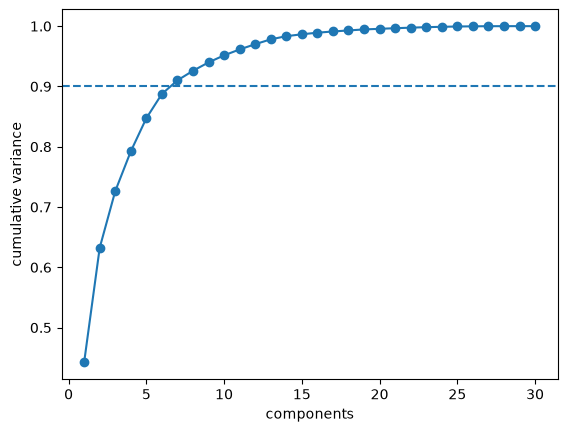

2 CV of distances 0.538
5 CV of distances 0.492
10 CV of distances 0.475
20 CV of distances 0.493
30 CV of distances 0.441


In [10]:
z_bc = StandardScaler().fit_transform(cancer_x)
pca = PCA().fit(z_bc)
cum = np.cumsum(pca.explained_variance_ratio_)
print('components for 90%', np.argmax(cum>=.90)+1)
print('components for 95%', np.argmax(cum>=.95)+1)
plt.plot(np.arange(1,31), cum, marker='o'); plt.axhline(.9, ls='--'); plt.xlabel('components'); plt.ylabel('cumulative variance'); plt.show()
for d in [2,5,10,20,30]:
    distances = pairwise_distances(z_bc[:150,:d])
    vals = distances[np.triu_indices_from(distances,k=1)]
    print(d, 'CV of distances', round(vals.std()/vals.mean(),3))


In [11]:
loadings = pd.DataFrame(PCA(n_components=3).fit(z_bc).components_.T, index=cancer_x.columns, columns=['PC1','PC2','PC3'])
for pc in loadings:
    print(pc, loadings[pc].abs().nlargest(6).index.tolist())


PC1 ['mean concave points', 'mean concavity', 'worst concave points', 'mean compactness', 'worst perimeter', 'worst concavity']
PC2 ['mean fractal dimension', 'fractal dimension error', 'worst fractal dimension', 'mean radius', 'compactness error', 'mean area']
PC3 ['texture error', 'smoothness error', 'symmetry error', 'worst symmetry', 'radius error', 'perimeter error']


反思：90%解释方差回答了什么，没有回答什么？何时更愿意保留命名特征而不是使用主成分？


## Q10 综合工作流 Packet D


In [12]:
workflow = pd.read_csv(ASSET_DIR / 'packet-d-workflow-decision.csv')
boundaries = pd.read_csv(ASSET_DIR / 'packet-d-boundary-checklist.csv')
display(workflow)
display(boundaries)
assert set(workflow.inquiry_questions.str.cat(sep=' ').split()) >= {f'Q{i}' for i in range(1,11)}


,step,workflow_action,inquiry_questions,required_evidence,change_or_stop_condition
0,1,define object question target and grouping,Q1 Q2,data dictionary and structure audit,stop if observation unit or target cannot be d...
1,2,audit provenance structure and quality,Q3 Q4,characteristics missingness outliers duplicate...,change design if missingness or site is entang...
2,3,choose representation and similarity semantics,Q5 Q6,metric sensitivity and mixed-type comparison,reject a metric dominated by scale or arbitrar...
3,4,set sampling aggregation and transformation,Q7 Q8,sampling and transformation sensitivity,change if key subgroups disappear or informati...
4,5,choose dimensionality strategy,Q9,PCA loadings and feature option comparison,stop reduction if retained variance loses requ...
5,6,split when generalization or fitted preprocess...,Q8 Q10,preprocessing audit,reject any parameter fitted with validation or...
6,7,document evidence uncertainty and boundary,Q10,final readiness memo,do not claim clinical causal or deployment val...


,boundary_area,evidence_can_support,evidence_cannot_support
0,descriptive,describe patterns in the supplied historical r...,population prevalence or representativeness
1,association,identify observed relationships for teaching,causal effects of measurements or interventions
2,prediction,illustrate preparation effects,clinical utility safety calibration or externa...
3,missingness,locate missing values,identify mechanism without collection knowledge
4,site difference,show source distributions differ,attribute causes without source metadata
5,PCA,describe retained variance,preserve clinical meaning or predictive signal


## 最终反思

用Claim Evidence Reasoning Uncertainty Boundary Stop conditions重写你的Data readiness plan。明确引用Q1至Q10，并说明哪一项证据最可能改变当前决定。
